In [ ]:
'''Build and implement a robust, scalable end-to-end machine learning pipeline using Scikit-learn, covering data ingestion, feature engineering, model training, evaluation, and deployment, with reproducibility and modularity in mind.'''

'Apply unsupervised learning techniques (K-means, DBSCAN, hierarchical clustering) to segment customer \nbehavior,providing granular insights for targeted marketing strategies and customer retention programs.'

In [2]:
# import libraries
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
# load dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# select features and target
num_cols = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'year', 'month', 'day']
cat_cols = ['region', 'category', 'age_group']
X = df[num_cols + cat_cols]
y = df['units_sold']
X.head()

,unit_price,stock_level,expiry_days_remaining,covid_flag,year,month,day,region,category,age_group
0,45.38,4774,466,0,2025,10,12,Middle East,Chronic,0-12
1,75.49,4584,181,1,2020,9,15,South Asia,Chronic,26-45
2,22.51,3934,556,1,2020,2,26,Middle East,Vitamin,0-12
3,63.29,4544,330,0,2025,11,9,South Asia,Chronic,0-12
4,44.28,4284,590,0,2022,4,4,South America,Chronic,26-45


In [5]:
# split dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train size:", X_train.shape, "test size:", X_test.shape)

train size: (142392, 10) test size: (35598, 10)


In [6]:
# build scikit learn pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=20, max_depth=8, random_state=42))
])
pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['unit_price', 'stock_level',
                                                   'expiry_days_remaining',
                                                   'covid_flag', 'year',
                                                   'month', 'day']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['region', 'category',
                                                   'age_group'])])),
                ('regressor',
                 RandomForestRegressor(max_depth=8, n_estimators=20,
                                       random_state=42))])

In [7]:
# train pipeline model
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['unit_price', 'stock_level',
                                                   'expiry_days_remaining',
                                                   'covid_flag', 'year',
                                                   'month', 'day']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['region', 'category',
                                                   'age_group'])])),
                ('regressor',
                 RandomForestRegressor(max_depth=8, n_estimators=20,
                                       random_state=42))])

In [8]:
# evaluate pipeline model performance
y_pred = pipeline.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("mae:", round(mae, 2))
print("rmse:", round(rmse, 2))
print("r2:", round(r2, 4))

mae: 64.05
rmse: 82.58
r2: 0.9413


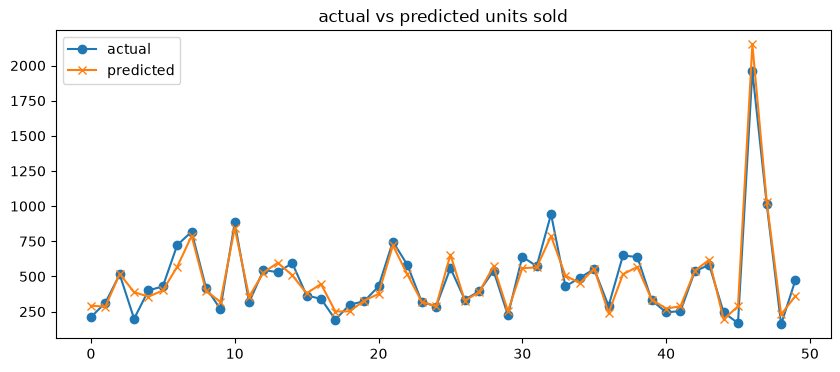

In [9]:
# easy plot of actual vs predicted sales
plt.figure(figsize=(10, 4))
plt.plot(y_test.values[:50], label='actual', marker='o')
plt.plot(y_pred[:50], label='predicted', marker='x')
plt.title('actual vs predicted units sold')
plt.legend()
plt.show()

In [10]:
# save pipeline model for deployment
joblib.dump(pipeline, 'sales_model_pipeline.joblib')

['sales_model_pipeline.joblib']

In [11]:
# test deployed pipeline on new sample
deployed_model = joblib.load('sales_model_pipeline.joblib')
sample = X_test.iloc[0:1]
prediction = deployed_model.predict(sample)
print("input features:", sample.to_dict(orient='records')[0])
print("predicted units sold:", round(prediction[0], 2))
print("actual units sold:", y_test.iloc[0])

input features: {'unit_price': 53.07, 'stock_level': 4601, 'expiry_days_remaining': 342, 'covid_flag': 0, 'year': 2023, 'month': 11, 'day': 3, 'region': 'Middle East', 'category': 'Antibiotic', 'age_group': '46-65'}
predicted units sold: 291.98
actual units sold: 211
